# Wine quality: regression, classification and clustering

Modelling wine quality from eleven physicochemical measurements: a simple linear regression, a k-nearest-neighbours classifier and k-means clustering, each with parameter tuning and evaluation.

See the README for the data source, the method and the main findings.

## 1. Data preparation and analysis

### 1.1 Sampling and cleaning

In [228]:
# Load the functions and file into python notebook
import pandas as pd
import numpy as np

In [229]:
# Import the csv
wine = pd.read_csv('data/wine_quality_raw.csv', delimiter=";", header=0, names=["fixed acidity","volatile acidity","citric acid","residual sugar","chlorides","free sulfur dioxide","total sulfur dioxide","density","pH","sulphates","alcohol","quality"])

In [230]:
# Check the data has been read correctly
wine

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45,170,1.001,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14,132,0.994,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30,97,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47,186,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47,186,0.9956,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...
4776,6.2,0.21,0.29,1.6,0.039,24,92,0.99114,3.27,0.50,11.2,6
4777,6.6,0.32,0.36,8,0.047,57,168,0.9949,3.15,0.46,9.6,5
4778,6.5,0.24,0.19,1.2,0.041,30,111,0.99254,2.99,0.46,9.4,6
4779,5.5,0.29,0.30,1.1,0.022,20,110,0.98869,3.34,0.38,12.8,7


In [231]:
# Get sample of 600 (Omitting rows with null values and duplicates)
wine_sample = wine.dropna().drop_duplicates().sample(n=600, random_state=32)
wine_sample

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4746,5.2,0.250,0.23,1.4,0.047,20,77,0.99001,3.32,0.62,11.4,5
2434,8.1,0.330,0.36,7.4,0.037,36,156,0.99592,3.19,0.54,10.6,6
3063,7.0,0.250,0.45,2.3,0.045,40,118,0.99064,3.16,0.48,11.9,7
1682,6.7,0.310,0.42,6.4,0.057,25,148,0.9955,3.16,0.45,9.6,5
3582,6.8,0.160,0.18,1.8,0.046,31,114,0.99226,3.27,0.55,10.8,6
...,...,...,...,...,...,...,...,...,...,...,...,...
2423,6.6,0.340,0.34,2.6,0.051,40.5,210,0.99314,3.15,0.61,10.0,5
481,7.2,0.400,0.62,10.8,0.041,70,189,0.9976,3.08,0.49,8.6,4
3862,6.0,0.210,0.30,8.7,0.036,47,127,0.99368,3.18,0.39,10.6,5
2162,6.4,0.330,0.24,9.8,0.041,29,109,0.9956,3.29,0.47,10.1,6


In [232]:
# Check the sample of 600 has no null values
wine_sample.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [233]:
# Check the value counts - Interestingly only two wines are rated with a low score of 3. This will affect models.
wine_sample['quality'].value_counts()

6    271
5    189
7     99
8     20
4     19
3      2
Name: quality, dtype: int64

In [234]:
# Check data types
wine_sample.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar           object
chlorides               float64
free sulfur dioxide      object
total sulfur dioxide     object
density                  object
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [235]:
# Remove white space as unable to change to float otherwise
wine_sample = wine_sample[wine_sample['residual sugar'] != " "]
wine_sample = wine_sample[wine_sample['free sulfur dioxide'] != " "]
wine_sample = wine_sample[wine_sample['total sulfur dioxide'] != " "]
wine_sample = wine_sample[wine_sample['density'] != " "]

In [236]:
# Change data types to 'float'
wine_sample['residual sugar'] = wine_sample['residual sugar'].astype(float)
wine_sample['free sulfur dioxide'] = wine_sample['free sulfur dioxide'].astype(float)
wine_sample['total sulfur dioxide'] = wine_sample['total sulfur dioxide'].astype(float)
wine_sample['density'] = wine_sample['density'].astype(float)

In [237]:
# check there are no duplicates
wsdups = wine_sample[wine_sample.duplicated()]
print(wsdups)

Empty DataFrame
Columns: [fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol, quality]
Index: []


In [238]:
# Double check all variables are now ints or floats
wine_sample.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [239]:
#View dataframe before saving as csv
wine_sample

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4746,5.2,0.250,0.23,1.4,0.047,20.0,77.0,0.99001,3.32,0.62,11.4,5
2434,8.1,0.330,0.36,7.4,0.037,36.0,156.0,0.99592,3.19,0.54,10.6,6
3063,7.0,0.250,0.45,2.3,0.045,40.0,118.0,0.99064,3.16,0.48,11.9,7
1682,6.7,0.310,0.42,6.4,0.057,25.0,148.0,0.99550,3.16,0.45,9.6,5
3582,6.8,0.160,0.18,1.8,0.046,31.0,114.0,0.99226,3.27,0.55,10.8,6
...,...,...,...,...,...,...,...,...,...,...,...,...
2423,6.6,0.340,0.34,2.6,0.051,40.5,210.0,0.99314,3.15,0.61,10.0,5
481,7.2,0.400,0.62,10.8,0.041,70.0,189.0,0.99760,3.08,0.49,8.6,4
3862,6.0,0.210,0.30,8.7,0.036,47.0,127.0,0.99368,3.18,0.39,10.6,5
2162,6.4,0.330,0.24,9.8,0.041,29.0,109.0,0.99560,3.29,0.47,10.1,6


In [240]:
# Save dataframe as csv
wine_sample.to_csv("data/wine_quality_sample.csv")

### 1.2 Alcohol and density: simple linear regression

In [241]:
# load packages
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [242]:
# create new variable for sample (for ease of use)
wines = wine_sample

In [243]:
wines['alcohol']

4746    11.4
2434    10.6
3063    11.9
1682     9.6
3582    10.8
        ... 
2423    10.0
481      8.6
3862    10.6
2162    10.1
1105     9.2
Name: alcohol, Length: 599, dtype: float64

Linear Model: alcohol = -338.45 * density + 346.94
Pearson Correlation Coefficient (r): -0.77
R-squared (R^2) Score: 0.60


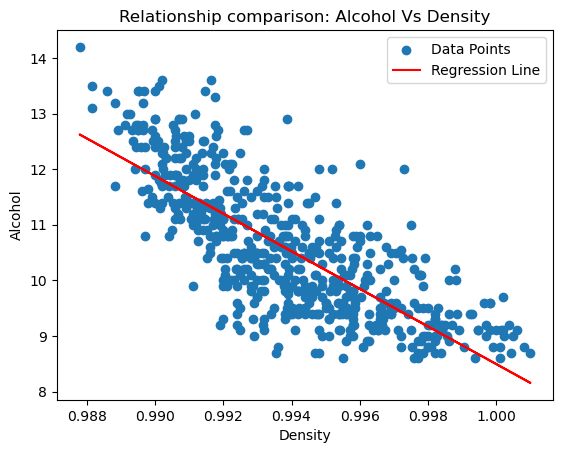

In [244]:
# Create scatterplot with Linear Regression line and coefficients printed
from sklearn.metrics import r2_score

density = wines['density'].values
alcohol = wines['alcohol'].values

# Reshape the data 
density = density.reshape(-1, 1)  # Reshape to a 2D array

# Create and fit the linear regression model
model = LinearRegression()
model.fit(density, alcohol)

# Get the coefficients of the model
slope = model.coef_[0]  # Coefficient (slope)
intercept = model.intercept_  # Intercept

# Print the linear model equation
print(f"Linear Model: alcohol = {slope:.2f} * density + {intercept:.2f}")

# Print R
pearson_corr = np.corrcoef(density.flatten(), alcohol)[0, 1]
print(f"Pearson Correlation Coefficient (r): {pearson_corr:.2f}")

# Print R-squared
y_pred = model.predict(density)
r_squared = r2_score(alcohol, y_pred)
print(f"R-squared (R^2) Score: {r_squared:.2f}")

# Plot the regression line and scatter plot
plt.scatter(density, alcohol, label='Data Points')
plt.plot(density, model.predict(density), color='red', label='Regression Line')
plt.xlabel('Density')
plt.ylabel('Alcohol')
plt.title('Relationship comparison: Alcohol Vs Density')
plt.legend()
plt.show()

In [245]:
# Calculate RMSE
from sklearn.metrics import mean_squared_error
import math
# Calculate predictions using your linear regression model
y_pred = model.predict(density)  

# Calculate the mean squared error (MSE)
mse = mean_squared_error(alcohol, y_pred)

# Calculate the root mean squared error (RMSE)
rmse = np.sqrt(mse)

# Print the RMSE
print(f"RMSE: {rmse:.2f}")

RMSE: 0.77


### 1.3 Alcohol content by quality score

In [246]:
#Observe the rankings of win
wines['quality'].value_counts()

6    270
5    189
7     99
8     20
4     19
3      2
Name: quality, dtype: int64

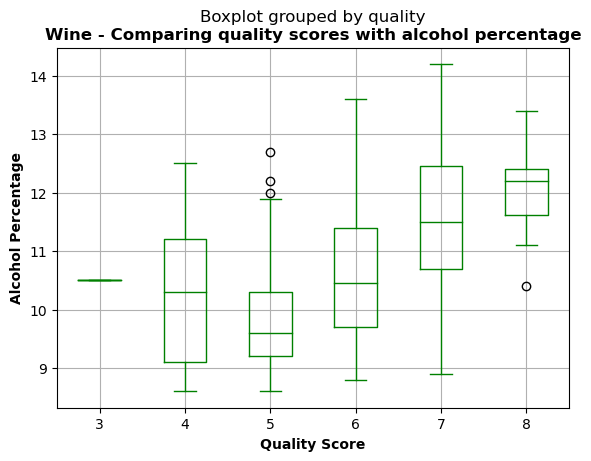

In [247]:
# Create the side-by-side boxplot for alcohol grouped by quality level.
wines.boxplot(column='alcohol',by='quality', fontsize=10, color='green')
plt.xlabel("Quality Score", weight='bold')
plt.ylabel("Alcohol Percentage", weight='bold')
plt.title("Wine - Comparing quality scores with alcohol percentage", weight='bold', fontsize=12)
plt.show()

## 2. Classification with k-nearest neighbours

### 2.1 Baseline model

In [248]:
# Create KNN Model
# Import relevant packages
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
import pylab as plt

# Seperate target data from other data
X = wines.iloc[:, 0:11]
y = wines['quality']

# Split data into testing/training
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)

#Create model starting with 3 neighbours
clf = KNeighborsClassifier(3)
fit = clf.fit(X_train, y_train)

#Fit model
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)

#Print results
print(cm)

#Print metrics
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  7  4  0  0]
 [ 0  3 55 49  6  0]
 [ 0  5 69 74 18  0]
 [ 0  1 25 21  8  0]
 [ 0  0  5  6  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.10      0.08      0.09        12
           5       0.34      0.49      0.40       113
           6       0.48      0.45      0.46       166
           7       0.24      0.15      0.18        55
           8       0.00      0.00      0.00        12

    accuracy                           0.38       360
   macro avg       0.19      0.19      0.19       360
weighted avg       0.37      0.38      0.37       360



### 2.2 Effect of the number of neighbours

Repeating the baseline model with different values of k.

In [249]:
# Using KNN with 2 neighbours
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
import pylab as plt
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(2)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  2  0  0  0]
 [ 0  1 10  1  0  0]
 [ 0  4 64 42  3  0]
 [ 0  4 82 73  7  0]
 [ 0  2 20 27  6  0]
 [ 0  0  4  7  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.09      0.08      0.09        12
           5       0.35      0.57      0.43       113
           6       0.49      0.44      0.46       166
           7       0.35      0.11      0.17        55
           8       0.00      0.00      0.00        12

    accuracy                           0.40       360
   macro avg       0.21      0.20      0.19       360
weighted avg       0.39      0.40      0.38       360



In [250]:
# KNN 4 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(4)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  2  0  0  0]
 [ 0  1  8  3  0  0]
 [ 0  1 58 44 10  0]
 [ 0  3 74 71 18  0]
 [ 0  0 22 26  7  0]
 [ 0  0  4  6  2  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.20      0.08      0.12        12
           5       0.35      0.51      0.41       113
           6       0.47      0.43      0.45       166
           7       0.19      0.13      0.15        55
           8       0.00      0.00      0.00        12

    accuracy                           0.38       360
   macro avg       0.20      0.19      0.19       360
weighted avg       0.36      0.38      0.36       360



In [251]:
# KNN 5 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(5)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  8  3  0  0]
 [ 0  2 59 45  7  0]
 [ 0  3 71 77 15  0]
 [ 0  1 21 26  7  0]
 [ 0  0  4  7  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.14      0.08      0.11        12
           5       0.36      0.52      0.43       113
           6       0.48      0.46      0.47       166
           7       0.23      0.13      0.16        55
           8       0.00      0.00      0.00        12

    accuracy                           0.40       360
   macro avg       0.20      0.20      0.19       360
weighted avg       0.38      0.40      0.38       360



In [252]:
# KNN 6 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(6)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  8  3  0  0]
 [ 0  2 61 45  5  0]
 [ 0  3 71 71 21  0]
 [ 0  0 21 28  6  0]
 [ 0  0  4  7  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.17      0.08      0.11        12
           5       0.37      0.54      0.44       113
           6       0.46      0.43      0.44       166
           7       0.18      0.11      0.14        55
           8       0.00      0.00      0.00        12

    accuracy                           0.39       360
   macro avg       0.20      0.19      0.19       360
weighted avg       0.36      0.39      0.37       360



In [253]:
# KNN 7 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(7)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  2  0  0  0]
 [ 0  1  9  2  0  0]
 [ 0  1 60 44  8  0]
 [ 0  0 70 73 23  0]
 [ 0  0 19 31  5  0]
 [ 0  0  4  6  2  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.50      0.08      0.14        12
           5       0.37      0.53      0.43       113
           6       0.47      0.44      0.45       166
           7       0.13      0.09      0.11        55
           8       0.00      0.00      0.00        12

    accuracy                           0.39       360
   macro avg       0.24      0.19      0.19       360
weighted avg       0.37      0.39      0.37       360



In [254]:
# KNN 8 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(8)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  9  2  0  0]
 [ 0  1 57 48  7  0]
 [ 0  0 68 83 15  0]
 [ 0  0 17 32  6  0]
 [ 0  0  3  7  2  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.50      0.08      0.14        12
           5       0.37      0.50      0.43       113
           6       0.48      0.50      0.49       166
           7       0.20      0.11      0.14        55
           8       0.00      0.00      0.00        12

    accuracy                           0.41       360
   macro avg       0.26      0.20      0.20       360
weighted avg       0.38      0.41      0.39       360



In [255]:
# KNN 9 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(9)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  8  3  0  0]
 [ 0  1 61 46  5  0]
 [ 0  0 62 88 16  0]
 [ 0  0 18 32  5  0]
 [ 0  0  4  4  4  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.50      0.08      0.14        12
           5       0.40      0.54      0.46       113
           6       0.51      0.53      0.52       166
           7       0.17      0.09      0.12        55
           8       0.00      0.00      0.00        12

    accuracy                           0.43       360
   macro avg       0.26      0.21      0.21       360
weighted avg       0.40      0.43      0.40       360



In [256]:
# KNN 10 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(10)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  8  3  0  0]
 [ 0  1 59 48  5  0]
 [ 0  1 65 85 15  0]
 [ 0  0 20 26  9  0]
 [ 0  0  4  6  2  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.33      0.08      0.13        12
           5       0.38      0.52      0.44       113
           6       0.50      0.51      0.51       166
           7       0.29      0.16      0.21        55
           8       0.00      0.00      0.00        12

    accuracy                           0.43       360
   macro avg       0.25      0.21      0.21       360
weighted avg       0.41      0.43      0.41       360



In [257]:
# KNN 11 Neighbours
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(11)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  6  5  0  0]
 [ 0  1 56 53  3  0]
 [ 0  0 67 86 13  0]
 [ 0  0 19 31  5  0]
 [ 0  0  4  6  2  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.50      0.08      0.14        12
           5       0.37      0.50      0.42       113
           6       0.47      0.52      0.49       166
           7       0.22      0.09      0.13        55
           8       0.00      0.00      0.00        12

    accuracy                           0.41       360
   macro avg       0.26      0.20      0.20       360
weighted avg       0.38      0.41      0.38       360



In [258]:
# KNN 10 Neighbours + p = 1
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  8  3  0  0]
 [ 0  0 63 45  5  0]
 [ 0  1 65 91  9  0]
 [ 0  0 18 33  4  0]
 [ 0  0  4  7  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.50      0.08      0.14        12
           5       0.40      0.56      0.46       113
           6       0.51      0.55      0.53       166
           7       0.21      0.07      0.11        55
           8       0.00      0.00      0.00        12

    accuracy                           0.44       360
   macro avg       0.27      0.21      0.21       360
weighted avg       0.41      0.44      0.41       360



### 2.3 Effect of the train/test split

Using the best k from above, the model is retrained on different train/test split ratios.

In [259]:
# Using KNN with 10 neighbours, the test_size parameter will be experimented with to find out what optimises the result
# 20:80
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  0  0  0]
 [ 0  0  3  4  0  0]
 [ 0  0 18 21  1  0]
 [ 0  0 15 36  4  0]
 [ 0  0  2  6  5  0]
 [ 0  0  1  2  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.45      0.45      0.45        40
           6       0.52      0.65      0.58        55
           7       0.45      0.38      0.42        13
           8       0.00      0.00      0.00         4

    accuracy                           0.49       120
   macro avg       0.24      0.25      0.24       120
weighted avg       0.44      0.49      0.46       120



In [260]:
# 30:70
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  2  0  0  0]
 [ 0  0  5  2  0  0]
 [ 0  0 28 28  3  0]
 [ 0  0 21 54  9  0]
 [ 0  0  3 15  5  0]
 [ 0  0  0  4  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         7
           5       0.47      0.47      0.47        59
           6       0.52      0.64      0.58        84
           7       0.28      0.22      0.24        23
           8       0.00      0.00      0.00         5

    accuracy                           0.48       180
   macro avg       0.21      0.22      0.22       180
weighted avg       0.44      0.48      0.46       180



In [261]:
# 40:60
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.40,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  2  0  0  0]
 [ 0  2  5  3  0  0]
 [ 0  0 43 35  2  0]
 [ 0  0 30 68 11  0]
 [ 0  0  8 16  7  0]
 [ 0  0  1  5  2  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       1.00      0.20      0.33        10
           5       0.48      0.54      0.51        80
           6       0.54      0.62      0.58       109
           7       0.32      0.23      0.26        31
           8       0.00      0.00      0.00         8

    accuracy                           0.50       240
   macro avg       0.39      0.26      0.28       240
weighted avg       0.49      0.50      0.48       240



In [262]:
# 50:50
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.50,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  2  3  5  0  0]
 [ 0  0 50 40  6  0]
 [ 0  0 45 82 15  0]
 [ 0  0 13 21  6  0]
 [ 0  0  3  5  2  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       1.00      0.20      0.33        10
           5       0.43      0.52      0.47        96
           6       0.53      0.58      0.55       142
           7       0.21      0.15      0.17        40
           8       0.00      0.00      0.00        10

    accuracy                           0.47       300
   macro avg       0.36      0.24      0.26       300
weighted avg       0.45      0.47      0.45       300



In [263]:
# 60:40
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.60,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  1  1  0  0]
 [ 0  1  8  3  0  0]
 [ 0  0 63 45  5  0]
 [ 0  1 65 91  9  0]
 [ 0  0 18 33  4  0]
 [ 0  0  4  7  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.50      0.08      0.14        12
           5       0.40      0.56      0.46       113
           6       0.51      0.55      0.53       166
           7       0.21      0.07      0.11        55
           8       0.00      0.00      0.00        12

    accuracy                           0.44       360
   macro avg       0.27      0.21      0.21       360
weighted avg       0.41      0.44      0.41       360



In [264]:
# 70:30
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.70,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[ 0  0  2  0  0  0]
 [ 0  0  7  7  0  0]
 [ 0  0 67 49  8  0]
 [ 0  0 86 89 23  0]
 [ 0  0 20 38 11  0]
 [ 0  0  5  4  4  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        14
           5       0.36      0.54      0.43       124
           6       0.48      0.45      0.46       198
           7       0.24      0.16      0.19        69
           8       0.00      0.00      0.00        13

    accuracy                           0.40       420
   macro avg       0.18      0.19      0.18       420
weighted avg       0.37      0.40      0.38       420



In [265]:
# 80:20
X = wines.iloc[:, 0:11]
y = wines['quality'] 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.80,random_state=0)
clf = KNeighborsClassifier(10, p=1)
fit = clf.fit(X_train, y_train)
predicted = fit.predict(X_test)
cm = confusion_matrix(y_test, predicted)
print(cm)
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted))

[[  0   0   2   0   0   0]
 [  0   0   7   7   1   0]
 [  0   0  69  68   9   0]
 [  0   0  91 104  22   0]
 [  0   0  29  40  12   0]
 [  0   0   8   9   2   0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        15
           5       0.33      0.47      0.39       146
           6       0.46      0.48      0.47       217
           7       0.26      0.15      0.19        81
           8       0.00      0.00      0.00        19

    accuracy                           0.39       480
   macro avg       0.18      0.18      0.17       480
weighted avg       0.35      0.39      0.36       480



## 3. Clustering with k-means

### 3.1 Building and tuning the model

In [274]:
# importing relevant packages
from sklearn import cluster
import pandas as pd

In [286]:
# Check data sample is still readable
wines

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,cluster
4746,5.2,0.250,0.23,1.4,0.047,20.0,77.0,0.99001,3.32,0.62,11.4,5,5
2434,8.1,0.330,0.36,7.4,0.037,36.0,156.0,0.99592,3.19,0.54,10.6,6,0
3063,7.0,0.250,0.45,2.3,0.045,40.0,118.0,0.99064,3.16,0.48,11.9,7,3
1682,6.7,0.310,0.42,6.4,0.057,25.0,148.0,0.99550,3.16,0.45,9.6,5,3
3582,6.8,0.160,0.18,1.8,0.046,31.0,114.0,0.99226,3.27,0.55,10.8,6,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2423,6.6,0.340,0.34,2.6,0.051,40.5,210.0,0.99314,3.15,0.61,10.0,5,2
481,7.2,0.400,0.62,10.8,0.041,70.0,189.0,0.99760,3.08,0.49,8.6,4,2
3862,6.0,0.210,0.30,8.7,0.036,47.0,127.0,0.99368,3.18,0.39,10.6,5,3
2162,6.4,0.330,0.24,9.8,0.041,29.0,109.0,0.99560,3.29,0.47,10.1,6,1


In [276]:
# Create pandas dataframe excluding target variable
X = pd.DataFrame(wines.drop(columns='quality'))

In [277]:
# Create and fit k-means model
kmeans = KMeans(n_clusters = 6, random_state = 25)
results = kmeans.fit_predict(X)

In [278]:
# Create cluster lables
ines['cluster'] = kmeans.labels_

In [279]:
print(results)

[5 0 3 3 1 3 3 3 1 2 2 5 3 3 5 1 0 3 0 3 3 5 0 3 3 3 1 0 3 1 3 2 5 1 1 1 1
 0 1 1 1 3 3 1 3 2 1 3 3 3 0 0 2 3 2 3 2 3 1 3 3 1 0 0 1 1 3 3 0 5 0 3 5 1
 0 1 1 0 2 1 0 5 3 1 0 1 3 0 1 3 0 2 3 2 2 2 1 0 3 2 0 1 5 5 1 0 0 0 0 0 2
 2 0 3 0 1 1 3 3 0 1 3 3 0 0 3 3 5 1 3 0 3 0 3 1 3 1 2 0 3 1 0 5 0 3 5 2 0
 0 1 3 5 1 1 5 3 2 5 2 1 2 1 0 1 3 5 1 0 2 0 3 0 3 3 3 2 5 3 2 3 1 3 1 0 3
 1 0 3 3 1 5 3 1 2 1 3 1 2 0 3 1 3 3 2 1 0 2 0 0 1 3 3 3 1 1 3 3 3 0 2 3 2
 3 2 3 3 0 3 1 2 1 1 3 1 1 5 0 0 3 3 1 1 5 2 2 3 3 1 5 1 0 5 3 1 1 1 1 1 3
 2 3 3 2 5 1 0 1 2 0 1 3 1 0 1 0 3 3 0 1 3 3 1 3 5 5 5 5 0 0 0 0 2 1 0 1 3
 3 2 5 1 2 5 2 1 1 2 2 1 3 3 0 3 2 0 0 2 5 0 0 0 0 1 1 0 1 0 3 2 0 1 3 0 1
 0 3 1 2 1 0 0 1 2 1 0 0 0 0 1 0 3 1 3 1 3 5 2 2 2 5 0 0 1 0 1 2 0 3 1 1 1
 0 1 3 0 1 1 0 0 3 3 2 1 0 5 0 1 0 0 3 3 0 0 2 3 0 3 5 0 2 0 2 0 3 0 2 1 0
 0 5 3 2 2 0 3 2 3 0 0 3 3 1 0 0 0 5 1 0 3 2 1 0 3 0 1 0 0 2 0 1 3 1 1 5 0
 1 0 3 3 1 1 1 0 3 0 3 2 3 2 1 3 0 1 2 3 2 1 3 1 3 3 5 0 1 3 3 0 3 1 1 0 4
 1 1 0 1 3 3 1 0 0 1 1 1 

In [282]:
# Check performance of model
from sklearn.metrics import silhouette_score
silhouette_avg = silhouette_score(X, results)
print(f"Silhouette Score: {silhouette_avg}")

Silhouette Score: 0.3461912656606068


In [284]:
# Create a loop to print silhouette scores for model with different k values
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=0, init='k-means++')
    cluster_labels = kmeans.fit_predict(X)
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(f"K={k}, Silhouette Score: {silhouette_avg}")

K=2, Silhouette Score: 0.49331706788490415
K=3, Silhouette Score: 0.4055009250294652
K=4, Silhouette Score: 0.39935034238392936
K=5, Silhouette Score: 0.3859554812836907
K=6, Silhouette Score: 0.3461912656606068
K=7, Silhouette Score: 0.31644089834986033


K=8, Silhouette Score: 0.3193961151581513
K=9, Silhouette Score: 0.3269224671977959


In [285]:
# Create a loop to check which init_method performs better - both are the same
init_methods = ['k-means++', 'random']
for init_method in init_methods:
    kmeans = KMeans(n_clusters=3, random_state=0, init=init_method)
    cluster_labels = kmeans.fit_predict(X)
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(f"Initialization Method: {init_method}, Silhouette Score: {silhouette_avg}")

Initialization Method: k-means++, Silhouette Score: 0.4055009250294652
Initialization Method: random, Silhouette Score: 0.4055009250294652


### 3.2 Choosing the number of clusters

In [178]:
from sklearn.cluster import KMeans

In [295]:
X = pd.DataFrame(wines.iloc[:,:11])
X

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
4746,5.2,0.250,0.23,1.4,0.047,20.0,77.0,0.99001,3.32,0.62,11.4
2434,8.1,0.330,0.36,7.4,0.037,36.0,156.0,0.99592,3.19,0.54,10.6
3063,7.0,0.250,0.45,2.3,0.045,40.0,118.0,0.99064,3.16,0.48,11.9
1682,6.7,0.310,0.42,6.4,0.057,25.0,148.0,0.99550,3.16,0.45,9.6
3582,6.8,0.160,0.18,1.8,0.046,31.0,114.0,0.99226,3.27,0.55,10.8
...,...,...,...,...,...,...,...,...,...,...,...
2423,6.6,0.340,0.34,2.6,0.051,40.5,210.0,0.99314,3.15,0.61,10.0
481,7.2,0.400,0.62,10.8,0.041,70.0,189.0,0.99760,3.08,0.49,8.6
3862,6.0,0.210,0.30,8.7,0.036,47.0,127.0,0.99368,3.18,0.39,10.6
2162,6.4,0.330,0.24,9.8,0.041,29.0,109.0,0.99560,3.29,0.47,10.1


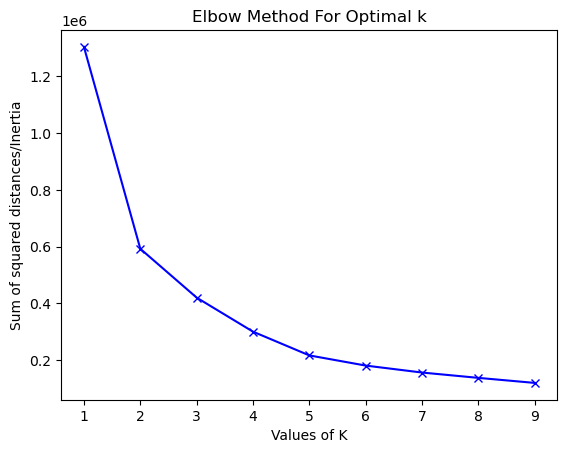

In [296]:
# create Elbow Method graph to identify most optimal value for k
Sum_of_squared_distances = []
K = range(1,10)
for num_clusters in K :
 kmeans = KMeans(n_clusters=num_clusters)
 kmeans.fit(X)
 Sum_of_squared_distances.append(kmeans.inertia_)
plt.plot(K,Sum_of_squared_distances,"bx-")
plt.xlabel("Values of K") 
plt.ylabel("Sum of squared distances/Inertia") 
plt.title("Elbow Method For Optimal k")
plt.show()

In [297]:
# Fit the model with the most optimal k value
model = cluster.KMeans(n_clusters = 2, random_state = 25)
results = model.fit_predict(X)

In [298]:
# Double check silhouette score remains the same as the loop earlier
from sklearn.metrics import silhouette_score
silhouette_avg = silhouette_score(X, results)
print(f"Silhouette Score: {silhouette_avg}")

Silhouette Score: 0.49378931202215504


### 3.3 Comparing clusters with the true quality scores

In [299]:
from sklearn.metrics import confusion_matrix

In [300]:
X = pd.DataFrame(wines.drop(columns='quality'))

In [301]:
kmeans = KMeans(n_clusters = 2, random_state = 25)

In [302]:
cluster_labels = kmeans.fit_predict(X)

In [304]:
# Create a new pandas dataframe with clustering results
cluster_df = pd.DataFrame({'Cluster': cluster_labels, 'Quality': wines['quality']})

In [305]:
# Create new cluster stats variable which shows the mean value of wine quality in each cluster.
cluster_stats = cluster_df.groupby('Cluster')['Quality'].mean()

In [306]:
# Display clusters with the mean quality score of each
print(cluster_stats)

Cluster
0    5.681992
1    5.967456
Name: Quality, dtype: float64


In [313]:
#Create confusion matrix
cm = confusion_matrix(cluster_df['Quality'], cluster_df['Cluster'])

In [315]:
#format confusion matrix
cm = cm[2:,:2]

In [316]:
#display confusion matrix
print(cm)

[[  2   0]
 [  6  13]
 [103  86]
 [118 152]
 [ 26  73]
 [  6  14]]


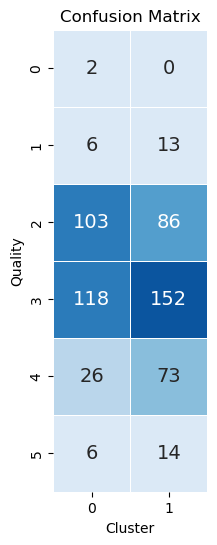

In [318]:
# Improve appearance of confusion matrix
import seaborn as sns

# Set up a color map
cmap = sns.color_palette("Blues")

# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False, square=True, linewidths=0.5, annot_kws={"size": 14})

# Customize plot labels and titles
plt.xlabel("Cluster")
plt.ylabel("Quality")
plt.title("Confusion Matrix")

# Show the plot
plt.show()